# Pollutants, weather and air quality in Italy

**Presentation-ordered analysis notebook**

The analysis follows the final slide sequence from climate anomalies and correlations through ozone, rainfall, dry spells, lagged rainfall, ventilation, humidity and stagnation, and finally the threshold summaries. Each figure is preceded by the calculation it needs; reusable data and summaries are built once and shared downstream. Plot titles and slide annotations remain in Google Slides.

Run from the project root in a fresh kernel. Edit the shared configuration cell near the top before running. The notebook expects `data/processed/raw.csv` and `daily_indices.csv.gz`.

## Shared configuration

In [54]:
# Shared imports and project configuration
import gc
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from scipy.special import gammaln
from scipy.stats import rankdata
from IPython.display import display
from matplotlib.colors import (
    LinearSegmentedColormap, ListedColormap, to_rgba, to_hex,
)
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

warnings.filterwarnings("ignore")
pd.set_option("display.width", 180, "display.max_columns", 120)
sns.set_theme(style="whitegrid", context="notebook")

# Shared analysis settings
STATION_COL, TIME_COL = "AirQualityStation", "time"
WET_MM, HEAVY_MM = 1.0, 10.0
ANOM_WINDOW = 31
MIN_PAIRS = 200
CORR_SAMPLE_N = 400_000
RANDOM_SEED = 42
BOOTSTRAP_REPS = 2_000
MIN_COMPARE_N = 5
MIN_STATIONS_FOR_BOX = 5
MIN_LOCAL_DAYS = 30
MIN_STATION_GROUP_DAYS = 5
DRY_SPELL_DAYS = 3
RH_ROLLING_DAYS = 3
LOCAL_Q_LOW, LOCAL_Q_HIGH = 0.25, 0.75
WINTER_MONTHS = [12, 1, 2]
AQHI_THRESHOLD = 7.0           # Editable cutoff for the continuous AQHI proxy
AQI_CLASS_THRESHOLD = 4          # Separate class cutoff for the presentation AQI panel
FISHER_RESAMPLES = 20_000      # Monte Carlo tables for Fisher-Freeman-Halton tests
FISHER_RANDOM_SEED = 42
DRY_STREAK_MAX = 15
RAIN_BIN_EDGES = [-float("inf"), 1, 5, 10, 15, 20, 25, float("inf")]
RAIN_BIN_LABELS = ["< 1", "1–5", "5–10", "10–15", "15–20", "20–25", "> 25"]

RAIN_DOSE_FIGSIZE = (12.5, 3.5)
RAIN_DOSE_YLIM = (0.62, 1.12)
RAIN_DOSE_YTICKS = [0.7, 0.8, 0.9, 1.0]
RAIN_DOSE_MARKER = "o"

# Project paths. Run the notebook from the repository root.
DATA_DIR = Path("data/processed")
RAW_PATH = DATA_DIR / "raw.csv"
IDX_PATH = DATA_DIR / "daily_indices.csv.gz"
FINAL_FIGURE_DIR = Path("Final_figures")
FINAL_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Global plot appearance. These are the only shared color/style definitions.
FIG_BG = "#f5f5f0"
GRID_COLOR = "#e3e3e3"
GRID_ALPHA = 0.55
SPINES_TO_HIDE = ("top", "right")
SPINE_WIDTH = 0.8

LINE_ALPHA_PRIMARY = 1.0
LINE_ALPHA_SECONDARY = 0.6
LINEWIDTH_PRIMARY = 2.4
LINEWIDTH_SECONDARY = 1.2
MARKERSIZE_PRIMARY = 6.0
MARKERSIZE_SECONDARY = 3.0

# Stagnation boxplot styling (kept here with the other presentation controls).
BOX_FACE_ALPHA = 0.8
BOX_WIDTH = 0.45
BOX_SPACING = 0.75
BOX_FIG_WIDTH_PER_POLLUTANT = 1.3
BOX_FIG_HEIGHT = 9
BOX_FONT = "Inter"
BOX_NEUTRAL = "#555555"
BOX_YLABEL = "Change in % at each monitoring station"
NEUTRAL_LINE_COLOR = "#666666"
ANOMALY_FILL_ALPHA = 0.22

POLLUTANT_ORDER = ["NO2", "NO", "CO", "PM10", "PM25", "O3", "SO2"]
BOLD_POLLUTANTS = {"NO", "PM25", "O3"}
PRIMARY_COLORS = {
    "NO2": "#1D4F96",
    "NO": "#5DA9E9",
    "CO": "#1A9C8F",
    "PM10": "#F08A2C",
    "PM25": "#A84E1A",
    "O3": "#D6337A",
    "SO2": "#8A63C9",
}
POLLUTANT_LABELS = {p: ("PM2.5" if p == "PM25" else p) for p in POLLUTANT_ORDER}

SECONDARY_COLORS = {
    "NO2": "#567BB0",
    "NO": "#86BEEE",
    "CO": "#53B5AB",
    "PM10": "#F4A761",
    "PM25": "#BE7A53",
    "O3": "#E0669B",
    "SO2": "#A78AD6",
}

INTER_FONT_PATH = "data\\external\\Inter-4.1\\extras\\ttf\\Inter-Regular.ttf"   # a list of .ttf paths
fm.fontManager.addfont(INTER_FONT_PATH)
plt.rcParams.update({
    "figure.facecolor": FIG_BG,
    "axes.facecolor": FIG_BG,
    "text.color": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "grid.color": GRID_COLOR,
    "figure.dpi": 110,
    "savefig.dpi": 600,
    "font.family": ["Inter", "DejaVu Sans"],
    "axes.spines.top": False,
    "axes.spines.right": False,
})

def pollutant_key(label):
    """Normalize PM2.5 spellings to the single palette key PM25."""
    key = str(label).strip().upper().replace(".", "")
    return "PM25" if key in {"PM25", "PM2.5"} else key

def style_figure(fig):
    """Apply the shared axes background, spine policy and pollutant line alpha."""
    fig.patch.set_facecolor(FIG_BG)
    primary_hex = {to_hex(c).lower() for c in PRIMARY_COLORS.values()}
    secondary_hex = {to_hex(c).lower() for c in SECONDARY_COLORS.values()}
    for ax in fig.axes:
        ax.set_facecolor(FIG_BG)
        for side in SPINES_TO_HIDE:
            ax.spines[side].set_visible(False)
        for spine in ax.spines.values():
            if spine.get_visible():
                spine.set_linewidth(SPINE_WIDTH)
        for line in ax.lines:
            try:
                color = to_hex(line.get_color()).lower()
            except (TypeError, ValueError):
                continue
            if color in primary_hex:
                line.set_alpha(LINE_ALPHA_PRIMARY)
            elif color in secondary_hex:
                line.set_alpha(LINE_ALPHA_SECONDARY)

def style_current_figure():
    """Apply the shared figure style before display or export."""
    style_figure(plt.gcf())


## Prepare the daily station grid

### Source columns and filters

In [55]:
# Source columns retained for the presentation analyses.
EXCLUDE_POLLUTANTS = {"NH3"}
CLIMATE_KEEP = ["CL_windspeed", "CL_blh", "CL_t2m", "CL_rh", "CL_ssr", "CL_tp"]
INDEX_COLS = ["AQI_hi", "AQHI_hi"]
FLAG_COLS = ["EX_PM10_WHO45", "EX_PM25_WHO15", "EX_NO2_WHO25"]
VLIM = 0.6


### Load concentrations and climate variables

In [56]:
EPOCH = pd.Timestamp("2000-01-01")

hdr = pd.read_csv(RAW_PATH, nrows=0).columns
poll_cols = [c for c in hdr if c.startswith("AQ_mean_") and c[len("AQ_mean_"):] not in EXCLUDE_POLLUTANTS]
cl_cols   = [c for c in CLIMATE_KEEP if c in hdr]
max_cols  = [f"AQ_max_{p}" for p in ("NO2", "O3", "SO2") if f"AQ_max_{p}" in hdr]
load_cols = poll_cols + cl_cols + max_cols
print("Pollutants:", [c[8:] for c in poll_cols], "| excluded:", sorted(EXCLUDE_POLLUTANTS))
print("Climate   :", cl_cols)
print("Daily maxima retained:", max_cols)

code_map, parts = {}, []
for ch in pd.read_csv(RAW_PATH, usecols=[STATION_COL, TIME_COL] + load_cols,
                      dtype={c: "float32" for c in load_cols}, parse_dates=[TIME_COL], chunksize=500_000):
    names = ch[STATION_COL].astype(str)
    for s in names.unique():
        code_map.setdefault(s, len(code_map))
    ch["st"]  = names.map(code_map).astype("int32")
    ch["day"] = (ch[TIME_COL].dt.normalize() - EPOCH).dt.days.astype("int32")
    parts.append(ch.drop(columns=[STATION_COL, TIME_COL]))
raw = pd.concat(parts, ignore_index=True); del parts; gc.collect()

stations = np.array(list(code_map))
S = len(stations)
d0, d1 = int(raw["day"].min()), int(raw["day"].max())
T = d1 - d0 + 1
N = S * T
dates = EPOCH + pd.to_timedelta(np.arange(d0, d1 + 1), unit="D")

pos = raw["st"].to_numpy().astype(np.int64) * T + (raw["day"].to_numpy() - d0)
dup = pd.Series(pos).duplicated().to_numpy()
keep = ~dup
A = {}
for c in load_cols:
    a = np.full(N, np.nan, np.float32)
    a[pos[keep]] = raw[c].to_numpy()[keep]
    if c in poll_cols or c in max_cols:
        a[a < 0] = np.nan                      # negative concentrations are not physical
    A[c] = a
print(f"raw rows {len(raw):,} (duplicates dropped: {dup.sum()}) -> grid {S} stations x {T} days = {N:,} rows ({N-len(raw)+dup.sum():,} filled with NaN)")
del raw, pos, keep, dup; gc.collect()


Pollutants: ['CO', 'NO', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2'] | excluded: ['NH3']
Climate   : ['CL_windspeed', 'CL_blh', 'CL_t2m', 'CL_rh', 'CL_ssr', 'CL_tp']
Daily maxima retained: ['AQ_max_NO2', 'AQ_max_O3', 'AQ_max_SO2']
raw rows 2,988,648 (duplicates dropped: 0) -> grid 744 stations x 4017 days = 2,988,648 rows (0 filled with NaN)


0

In [57]:
# ---- merge daily_indices -------------------------------------------------------------
print("daily_indices:", IDX_PATH)

avail = list(pd.read_csv(IDX_PATH, nrows=0).columns)
idx_cols = [c for c in INDEX_COLS + FLAG_COLS if c in avail]
print("indices loaded:", idx_cols, "| missing in file:", [c for c in INDEX_COLS + FLAG_COLS if c not in avail])
for c in idx_cols:
    A[c] = np.full(N, np.nan, np.float32)

def put(ch):
    st  = ch[STATION_COL].astype(str).map(code_map)
    day = (pd.to_datetime(ch[TIME_COL]).dt.normalize() - EPOCH).dt.days
    ok  = (st.notna() & day.between(d0, d1)).to_numpy()
    p   = st[ok].to_numpy().astype(np.int64) * T + (day[ok].to_numpy() - d0)
    for c in idx_cols:
        A[c][p] = pd.to_numeric(ch.loc[ok, c], errors="coerce").to_numpy(np.float32)
    return int(ok.sum())

n_match = 0
for ch in pd.read_csv(IDX_PATH, usecols=[STATION_COL, TIME_COL] + idx_cols, chunksize=500_000):
    n_match += put(ch)
print(f"index rows matched to the raw grid: {n_match:,}")

daily = pd.DataFrame(A); del A; gc.collect()
print(f"daily table: {daily.shape}, {daily.memory_usage().sum()/1e6:.0f} MB")


daily_indices: data\processed\daily_indices.csv.gz
indices loaded: ['AQI_hi', 'AQHI_hi', 'EX_PM10_WHO45', 'EX_PM25_WHO15', 'EX_NO2_WHO25'] | missing in file: []
index rows matched to the raw grid: 2,988,648
daily table: (2988648, 21), 251 MB


In [58]:
# ---- calendar and derived variables (all vectorised on (S, T) matrices) --------------------
cal_month  = dates.month.to_numpy().astype(np.int8)
cal_dow    = dates.dayofweek.to_numpy().astype(np.int8)
cal_year   = dates.year.to_numpy().astype(np.int16)
cal_season = np.array([0, 0, 1, 1, 1, 2, 2, 2, 3, 3, 3, 0])[cal_month - 1]        # 0 Winter(DJF) 1 Spring 2 Summer 3 Autumn
SEASONS    = ["Winter", "Spring", "Summer", "Autumn"]
YEARS      = np.unique(cal_year)

def g2(col):   return daily[col].to_numpy().reshape(S, T)
def flat(a2):  return np.ascontiguousarray(a2, dtype=np.float32).reshape(-1)

def shift2d(a, k):
    """value k days earlier (k>0) or later (k<0), NaN padded"""
    if k == 0: return a
    out = np.full_like(a, np.nan)
    if k > 0: out[:, k:] = a[:, :-k]
    else:     out[:, :k] = a[:, -k:]
    return out

daily["CL_vent"] = daily["CL_windspeed"] * daily["CL_blh"]          # ventilation coefficient: low = stagnant air

# ---- anomalies: value minus 31-day centred rolling mean (per station) --------------------------
def anomaly(a1d, window=ANOM_WINDOW):
    w = pd.DataFrame(a1d.reshape(S, T).T)                          # (T, S): all stations at once
    m = w.rolling(window, center=True, min_periods=window // 2).mean().to_numpy()
    return flat((w.to_numpy() - m).T)

idx_cols = [c for c in idx_cols if c in INDEX_COLS]                 # flags are not anomalised
AN_SRC = poll_cols + ["CL_windspeed", "CL_blh", "CL_vent", "CL_t2m", "CL_rh", "CL_ssr", "CL_tp"]
AN_SRC = [c for c in AN_SRC if c in daily]
daily = pd.concat([daily, pd.DataFrame({"AN_" + c: anomaly(daily[c].to_numpy()) for c in AN_SRC})], axis=1)
print(f"daily table: {daily.shape}, {daily.memory_usage().sum()/1e6:.0f} MB")
gc.collect()


daily table: (2988648, 36), 430 MB


0

In [59]:
# Shared correlation and heatmap helpers used by climate, ozone and lagged-rain analyses.
REN = {"windspeed": "wind", "blh": "BLH", "vent": "ventilation", "t2m": "temp", "tp": "rain", "ssr": "radiation", "rh": "humidity"}

def short(column):
    column = re.sub(r"^(?:AN_)?(?:AQ_mean_|CL_)?", "", column)
    return REN.get(column, column)

def D(columns):
    return {column: daily[column].to_numpy() for column in columns}

def spearman(y, x, mask=None):
    valid = ~(np.isnan(y) | np.isnan(x))
    if mask is not None:
        valid &= mask
    n = int(valid.sum())
    if n < MIN_PAIRS:
        return np.nan, n
    ranks_y, ranks_x = rankdata(y[valid]), rankdata(x[valid])
    ranks_y -= ranks_y.mean()
    ranks_x -= ranks_x.mean()
    denominator = np.sqrt((ranks_y * ranks_y).sum() * (ranks_x * ranks_x).sum())
    rho = float((ranks_y * ranks_x).sum() / denominator) if denominator > 0 else np.nan
    return rho, n

def corr_mat(Y, X, mask=None):
    return pd.DataFrame({
        x_name: {y_name: spearman(y, x, mask)[0] for y_name, y in Y.items()}
        for x_name, x in X.items()
    })

def heat(frame, ax, vmin=-VLIM, vmax=VLIM, cmap="RdBu_r", labels=None,
         fmt=".2f", cbar=True, fontsize=7, linewidths=0, linecolor=FIG_BG):
    data = frame.astype(float).copy()
    data.index = [short(value) for value in data.index]
    data.columns = [short(value) for value in data.columns]
    annotations = dict(annot=True, fmt=".2f") if labels is None else dict(annot=labels, fmt="")
    sns.heatmap(
        data, ax=ax, cmap=cmap, center=0 if cmap == "RdBu_r" else None,
        vmin=vmin, vmax=vmax, annot_kws={"size": fontsize}, cbar=cbar,
        cbar_kws={"shrink": 0.6}, linewidths=linewidths,
        linecolor=linecolor, **annotations,
    )

ALL_CL = [c for c in ["CL_windspeed", "CL_blh", "CL_vent", "CL_tp", "CL_t2m", "CL_rh", "CL_ssr"] if c in daily]
AN_P = ["AN_" + c for c in poll_cols]


## Raw values versus anomalies

The anomaly is the daily value minus its 31-day centred station-specific rolling mean. This removes much of the seasonal level before comparing short-term co-movement.

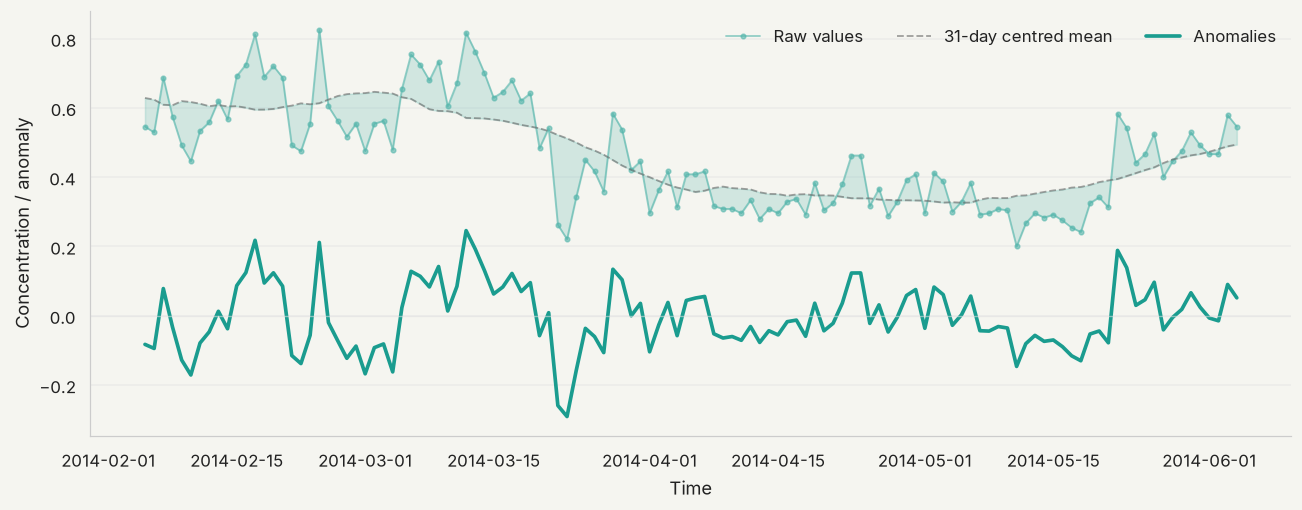

5268

In [60]:
# Plot configuration
ANOMALY_POLLUTANT = "CO"        # e.g. CO, NO2, PM10, PM2.5, O3, SO2
ANOMALY_STATION_INDEX = None    # None = station with most valid observations
ANOMALY_START = 400             # day offset within the selected station series
ANOMALY_LENGTH = 120
RAW_COLOR = SECONDARY_COLORS[pollutant_key(ANOMALY_POLLUTANT)]
ANOMALY_COLOR = PRIMARY_COLORS[pollutant_key(ANOMALY_POLLUTANT)]

poll_col = next((c for c in poll_cols if c.endswith("_" + ANOMALY_POLLUTANT)), None)
if poll_col is None:
    raise ValueError(f"No daily-mean column found for {ANOMALY_POLLUTANT!r}.")
anom_col = "AN_" + poll_col
raw_matrix = g2(poll_col)
anom_matrix = g2(anom_col)
station_idx = (
    int(ANOMALY_STATION_INDEX) if ANOMALY_STATION_INDEX is not None
    else int(np.nanargmax(np.isfinite(raw_matrix).sum(axis=1)))
)
start = max(0, min(int(ANOMALY_START), T - 2))
stop = min(T, start + int(ANOMALY_LENGTH))
x = dates[start:stop]
raw_y = raw_matrix[station_idx, start:stop]
anom_y = anom_matrix[station_idx, start:stop]
baseline_y = raw_y - anom_y

fig, ax = plt.subplots(figsize=(12, 4.8), facecolor=FIG_BG)
ax.plot(x, raw_y, "-o", ms=MARKERSIZE_SECONDARY, lw=LINEWIDTH_SECONDARY,
        color=RAW_COLOR, alpha=LINE_ALPHA_SECONDARY, label="Raw values")
ax.plot(x, baseline_y, ls="--", lw=LINEWIDTH_SECONDARY, color=NEUTRAL_LINE_COLOR,
        alpha=LINE_ALPHA_SECONDARY, label=f"{ANOM_WINDOW}-day centred mean")
ax.fill_between(x, raw_y, baseline_y, color=RAW_COLOR, alpha=ANOMALY_FILL_ALPHA)
ax.plot(x, anom_y, lw=LINEWIDTH_PRIMARY, color=ANOMALY_COLOR,
        alpha=LINE_ALPHA_PRIMARY, label="Anomalies")
ax.axhline(0, lw=0.9, color=GRID_COLOR, alpha=GRID_ALPHA)
ax.set_xlabel("Time")
ax.set_ylabel("Concentration / anomaly")
ax.legend(frameon=False, ncol=3)
ax.grid(axis="y", color=GRID_COLOR, alpha=GRID_ALPHA)
ax.grid(axis="x", visible=False)
plt.tight_layout()
style_current_figure()
plt.show()
del raw_matrix, anom_matrix, raw_y, anom_y, baseline_y
gc.collect()


## Climate–pollutant correlations

The two matrices compare Spearman correlations using raw daily values and 31-day anomalies. The anomaly matrix emphasizes short-term weather associations after removing the broad seasonal signal.

In [61]:
Y = D(poll_cols)
lv = corr_mat(Y, D(ALL_CL))
an = corr_mat(D(AN_P), D(["AN_" + c for c in ALL_CL]))
an.columns = lv.columns; an.index = lv.index


In [62]:

gamma = 0.8  # > 1 enhances the extremes

x = np.linspace(0, 1, 256)
x_gamma = 0.5 + 0.5 * np.sign(2*x - 1) * np.abs(2*x - 1)**(1/gamma)

colors = plt.cm.coolwarm(x_gamma)
cmap_custom = LinearSegmentedColormap.from_list(
    'coolwarm_gamma', colors
)


In [63]:


bounds = np.array([
    -0.65,
    -0.55, -0.35, -0.15, -0.05,
     0.05,  0.15,  0.35,  0.55,
     0.65
])

n_bins = len(bounds) - 1

# Sample the existing gamma-corrected colormap
colors = cmap_custom(np.linspace(0, 1, n_bins))
cmap_discrete = ListedColormap(colors)



# --------------------------------------------------
# Prepare data
# --------------------------------------------------

weather_order = ["rain", "humidity", "wind", "BLH", "ventilation",
                  "temp", "radiation"]

weather_cols = [
    c for label in weather_order
    for c in lv.columns if short(c) == label
]

pollutants_cols = [
    c for label in POLLUTANT_ORDER
    for c in lv.index if short(c) == label
]

lv_plot = lv.loc[pollutants_cols, weather_cols]
an_plot = an.loc[pollutants_cols, weather_cols]


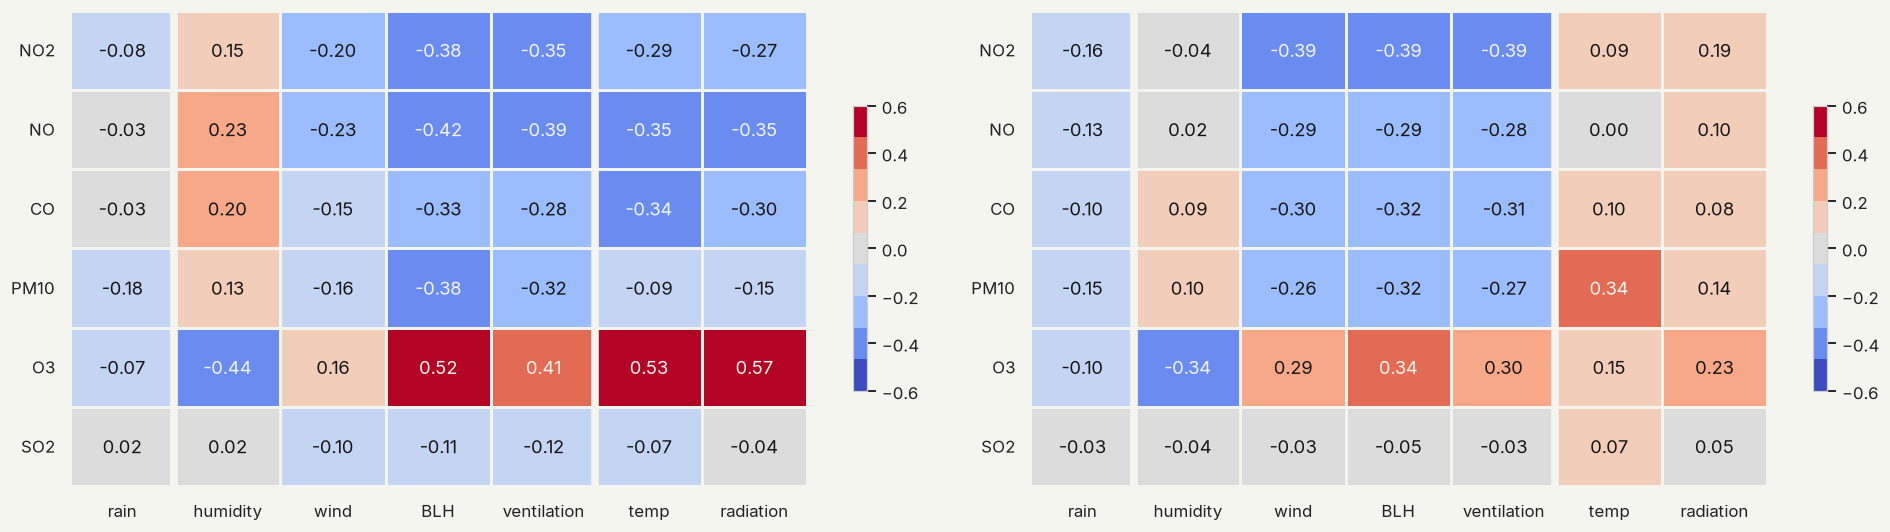

In [64]:
# --------------------------------------------------
# Plot heatmaps

# --------------------------------------------------

fig, ax = plt.subplots(
    1, 2, figsize=(18, 5), facecolor=FIG_BG
)

heat(
    lv_plot, ax[0],
    fontsize=12, linewidths=.9,
    cmap=cmap_discrete)

heat(
    an_plot, ax[1],
    fontsize=12, linewidths=.9,
    cmap=cmap_discrete
)


# --------------------------------------------------
# Formatting
# --------------------------------------------------

row_labels = [short(c) for c in lv.index]
column_labels = [short(c) for c in weather_cols]

for a in ax:
    for label in ("rain", "ventilation"):
        if label in column_labels and column_labels.index(label) < len(column_labels) - 1:
            a.axvline(
                column_labels.index(label) + 0.99,
                color=FIG_BG, linewidth=5
            )

    a.set_facecolor(FIG_BG)

ax[0].tick_params(axis="y", rotation=0)
ax[1].tick_params(axis="y", rotation=0)

for a in ax:
    for txt in a.texts:

        r, g, b = plt.matplotlib.colors.to_rgb(txt.get_color())
        if r < 0.5:
            txt.set_color("#171717")
        else:
            txt.set_color(FIG_BG)
 

plt.tight_layout()
style_current_figure()
plt.savefig("corr_matrix.png", dpi=1000)
plt.show()


## Shared station-day table

The station-day grid is converted once into the common long-format table used by the rainfall, ozone, ventilation, humidity and threshold analyses. Daily means, maxima, index columns and anomaly columns are passed through rather than re-read or re-derived.

In [65]:
# Reuse the prepared grid. All following sections use `df` as their one shared table.
n_stations, n_days = len(stations), len(dates)
mean_sources = {
    pollutant_key(column[len("AQ_mean_"):]): column
    for column in poll_cols
}
shared_data = {
    STATION_COL: np.repeat(stations, n_days),
    TIME_COL: np.tile(dates.to_numpy(dtype="datetime64[ns]"), n_stations),
}

POLL = [p for p in POLLUTANT_ORDER if p in mean_sources]
for pollutant in POLL:
    shared_data[pollutant] = daily[mean_sources[pollutant]].to_numpy(copy=False)

CLIMATE_RENAME = {
    "CL_windspeed": "wind", "CL_blh": "blh", "CL_vent": "vent",
    "CL_t2m": "t2m", "CL_rh": "rh", "CL_ssr": "ssr", "CL_tp": "tp",
}
for source, target in CLIMATE_RENAME.items():
    if source in daily.columns:
        shared_data[target] = daily[source].to_numpy(copy=False)

# Carry selected indices and pollutant maxima into the shared table.
for column in ["AQI_hi", "AQHI_hi", "EX_PM10_WHO45", "EX_PM25_WHO15", "EX_NO2_WHO25", "EX_O3_H180"]:
    if column in daily.columns:
        shared_data[column] = daily[column].to_numpy(copy=False)
for pollutant in ("NO2", "O3", "SO2"):
    source = f"AQ_max_{pollutant}"
    if source in daily.columns:
        shared_data[f"{pollutant}_max"] = daily[source].to_numpy(copy=False)

# Reuse the already computed anomalies from the initial climate analysis under concise canonical names.
for pollutant in POLL:
    source = mean_sources[pollutant]
    anomaly_col = f"AN_{source}"
    if anomaly_col in daily.columns:
        shared_data[f"an_{pollutant}"] = daily[anomaly_col].to_numpy(copy=False)
for source, target in {
    "AN_CL_windspeed": "an_wind", "AN_CL_blh": "an_blh",
    "AN_CL_vent": "an_vent", "AN_CL_t2m": "an_t2m",
    "AN_CL_rh": "an_rh", "AN_CL_ssr": "an_ssr", "AN_CL_tp": "an_rain",
}.items():
    if source in daily.columns:
        shared_data[target] = daily[source].to_numpy(copy=False)

df = pd.DataFrame(shared_data, copy=False)
del shared_data, mean_sources, CLIMATE_RENAME
print(
    f"Shared station-day table: {len(df):,} rows × {len(df.columns)} columns; "
    f"{len(POLL)} pollutant means reused from the source grid."
)

# Release the large Part-I frame; the shared table now owns all downstream inputs.
for _name in [
    "daily", "A", "raw", "code_map", "stations", "dates", "N", "S", "T",
    "d0", "d1", "pos", "dup", "keep", "poll_cols", "cl_cols", "idx_cols",
    "cal_month", "cal_dow", "cal_year", "cal_season", "SEASONS", "YEARS",
    "n_valid", "reg_lab", "reg_st", "area_st", "ub_st", "SCOPES", "GROUPS",
    "GROUP_NAMES", "KEY_CL", "ALL_CL", "AN_P", "lv", "an", "Y", "X",
    "AN_SRC", "save", "hdr", "EPOCH", "n_stations", "n_days",
    "max_cols", "load_cols",
]:
    globals().pop(_name, None)
gc.collect()

Shared station-day table: 2,988,648 rows × 38 columns; 7 pollutant means reused from the source grid.


19089

## Ozone: why is it different?

Ozone correlations use the same 31-day station-specific anomalies as the climate–pollutant matrices. The sample is drawn once and reused across all driver comparisons.

In [66]:
# Elaboration: sample a shared anomaly table for the focused ozone comparison.
O3_DRIVERS = [
    ("Temperature", "an_t2m"),
    ("Radiation", "an_ssr"),
    ("Boundary-layer height", "an_blh"),
    ("NO", "an_NO"),
    ("NO2", "an_NO2"),
]
O3_SAMPLE_COLS = ["an_O3"] + [column for _, column in O3_DRIVERS]
missing = [column for column in O3_SAMPLE_COLS if column not in df.columns]
if missing:
    raise KeyError(f"Missing ozone comparison inputs: {missing}")
samp = df[O3_SAMPLE_COLS].sample(
    min(CORR_SAMPLE_N, len(df)), random_state=RANDOM_SEED
)


In [67]:
# Focused O3 correlations with key meteorological drivers and co-pollutants.
# Uses the same 31-day deseasonalised anomalies and Spearman method as Figure 5.
o3_targets = O3_DRIVERS
missing = [column for _, column in o3_targets if column not in samp.columns]
if missing:
    raise KeyError(f"Missing O₃ correlation inputs: {missing}")

rows = []
for label, column in o3_targets:
    pair = samp[["an_O3", column]].dropna()
    rho = stats.spearmanr(pair["an_O3"], pair[column]).statistic
    rows.append({"factor": label, "spearman_rho": rho, "n_pairs": len(pair)})
o3_corr = pd.DataFrame(rows).set_index("factor")
display(o3_corr.round({"spearman_rho": 3}))


,spearman_rho,n_pairs
factor,,
Temperature,0.152,152350
Radiation,0.226,152350
Boundary-layer height,0.332,152350
NO,-0.428,31595
NO2,-0.376,139320


findfont: Failed to find font weight bold for Inter, now using 400.


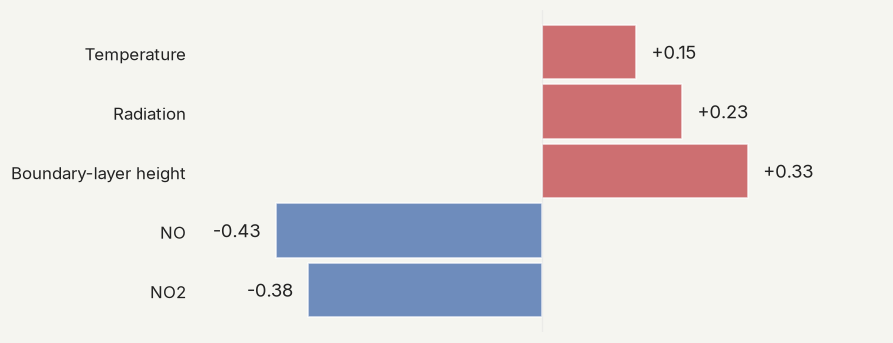

In [68]:
fig, ax = plt.subplots(figsize=(8, 3.8))
colors = ["C3" if value >= 0 else "C0" for value in o3_corr["spearman_rho"]]
ax.barh(o3_corr.index, o3_corr["spearman_rho"], height=.92, color=colors, alpha=.8)
ax.axvline(0, color=GRID_COLOR, alpha=GRID_ALPHA, lw=.8)
ax.set_xlim(-0.55, 0.55)
ax.set_xticklabels([])
for y, value in enumerate(o3_corr["spearman_rho"]):
    ax.text(value + (.025 if value >= 0 else -.025), y, f"{value:+.2f}",
            va="center", ha="left" if value >= 0 else "right", fontsize=12, fontweight="bold")
ax.invert_yaxis()
ax.grid(False, axis="both")
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(False)


style_current_figure()
plt.savefig("Final_figures/ozone corr.png")
plt.show()


## Shared rainfall, humidity and normalized-response features

Rainfall history, dry-spell position and three-day relative humidity are computed once on the complete station × day grid. The response summaries below process one pollutant at a time, reusing the same station-month normalization for the rain-dose, dry-spell and ventilation figures without retaining seven full-size temporary arrays.

In [69]:
# Establish the station-major grid layout used for time-aware features.
station_codes, station_names = pd.factorize(df[STATION_COL], sort=False)
ns = len(station_names)
nd = df[TIME_COL].nunique()
if ns * nd != len(df):
    raise ValueError("The shared station-day table is not a complete station × day grid.")
df["st"] = station_codes.astype("int32")
df["month"] = df[TIME_COL].dt.month.astype("int8")
df["dow"] = df[TIME_COL].dt.dayofweek.astype("int8")
df["sm"] = (df["st"] * 12 + df["month"] - 1).astype("int32")
df["tp_mm"] = pd.to_numeric(df["tp"], errors="coerce").astype("float32") * 1000.0

# Rain and dry-spell features. Unknown precipitation after the last observed rain
# invalidates the streak until a new wet day is observed.
tp_grid = df["tp_mm"].to_numpy(dtype="float32").reshape(ns, nd)
positions = np.broadcast_to(np.arange(nd, dtype=np.int32), (ns, nd))
rain_known = np.isfinite(tp_grid)
wet = rain_known & (tp_grid >= WET_MM)
unknown = ~rain_known
last_wet = np.maximum.accumulate(np.where(wet, positions, -1), axis=1)
last_unknown = np.maximum.accumulate(np.where(unknown, positions, -1), axis=1)
dry_run = (positions - last_wet).astype("float32")
dry_run[last_unknown > last_wet] = np.nan
no_wet_history = (last_wet == -1) & (last_unknown == -1)
dry_run[no_wet_history] = np.nan

df["RF_0"] = np.where(rain_known, wet.astype("float32"), np.nan).reshape(-1)
df["RF_heavy0"] = np.where(rain_known, (tp_grid >= HEAVY_MM).astype("float32"), np.nan).reshape(-1)
df["dry_run"] = dry_run.reshape(-1)
df["rain_known"] = np.isfinite(df["RF_0"])
df["rainy_today"] = df["RF_0"].eq(1)
df["rain_free_today"] = df["RF_0"].eq(0)
df["dry_spell"] = df["dry_run"].ge(DRY_SPELL_DAYS)

# Trailing three-day mean relative humidity, with the same minimum-period rule
# used in the earlier station-by-station implementation.
rh_grid = df["rh"].to_numpy(dtype="float32").reshape(ns, nd)
rh_3d = pd.DataFrame(rh_grid.T).rolling(RH_ROLLING_DAYS, min_periods=2).mean().to_numpy(dtype="float32").T
df["RH_3d_mean"] = rh_3d.reshape(-1)

print(
    f"Prepared {len(df):,} station-days across {ns:,} stations; "
    f"rain-known={df['rain_known'].mean():.1%}, "
    f"three-day RH available={df['RH_3d_mean'].notna().mean():.1%}."
)
del station_codes, station_names, tp_grid, positions, rain_known, wet, unknown
del last_wet, last_unknown, dry_run, no_wet_history, rh_grid, rh_3d
gc.collect()

Prepared 2,988,648 station-days across 744 stations; rain-known=100.0%, three-day RH available=100.0%.


236

In [70]:
# One categorical rainfall variable is shared by the distribution and dose-response figures.
RAIN_BINS = pd.cut(
    df["tp_mm"], bins=RAIN_BIN_EDGES, labels=RAIN_BIN_LABELS,
    right=False, ordered=True,
)
RAIN_COUNTS = RAIN_BINS.value_counts(sort=False, normalize=True).reindex(RAIN_BIN_LABELS)

# Set up the three ventilation predictors once. Their decile codes are shared
# across pollutants, so every pollutant is summarized against identical bins.
WIND_EFFECT_VARS = {
    "Wind speed (m/s)": "wind",
    "Boundary-layer height (m)": "blh",
    "Ventilation (m²/s)": "vent",
}
WIND_EFFECT_POLLUTANTS = [p for p in ("PM10", "NO2", "O3") if p in POLL]
WIND_CODES = {}
WIND_EFFECT_DATA = {}
for label, column in WIND_EFFECT_VARS.items():
    values = df[column].to_numpy(dtype="float32")
    edges = np.nanquantile(values[::7], np.linspace(0.1, 0.9, 9))
    codes = np.digitize(values, edges).astype("int8")
    codes[~np.isfinite(values)] = -1
    x_medians = pd.Series(values).groupby(codes).median().reindex(range(10)).to_numpy()
    WIND_CODES[label] = codes
    WIND_EFFECT_DATA[label] = (x_medians, {})

# Streak positions are exact calendar-day offsets 0–15; values after day 15 are
# not folded into the final bin.
dry_values = df["dry_run"].to_numpy(dtype="float32")
dry_codes = np.full(len(df), -1, dtype="int8")
dry_valid = np.isfinite(dry_values) & (dry_values >= 0) & (dry_values <= DRY_STREAK_MAX)
dry_codes[dry_valid] = dry_values[dry_valid].astype("int8")
dry_group = pd.Series(dry_codes, index=df.index)

# Build all station-month-normalized descriptive summaries in one pollutant loop.
# Only the small result tables are retained, plus PM25_NORM for the later humidity panel.
dose_columns = {}
dry_medians = {}
dry_counts = {}
PM25_NORM = None
for pollutant in POLL:
    station_month_median = df.groupby("sm", sort=False)[pollutant].transform("median")
    ratio = (df[pollutant] / station_month_median).astype("float32")
    ratio = ratio.where(np.isfinite(ratio))
    ratio_series = pd.Series(ratio.to_numpy(), index=df.index)

    dose_columns[pollutant] = ratio_series.groupby(RAIN_BINS, observed=False).median().reindex(RAIN_BIN_LABELS)
    dry_medians[pollutant] = ratio_series.groupby(dry_group).median().reindex(range(DRY_STREAK_MAX + 1))
    dry_counts[pollutant] = ratio_series.groupby(dry_group).count().reindex(range(DRY_STREAK_MAX + 1), fill_value=0).astype("int64")

    if pollutant in WIND_EFFECT_POLLUTANTS:
        for label, codes in WIND_CODES.items():
            WIND_EFFECT_DATA[label][1][pollutant] = (
                ratio_series.groupby(codes).median().reindex(range(10)).to_numpy(dtype=float)
            )
    if pollutant == "PM25":
        PM25_NORM = ratio_series

    del station_month_median, ratio, ratio_series
    gc.collect()

DOSE = pd.DataFrame(dose_columns).reindex(index=RAIN_BIN_LABELS)
DRY_STREAK_MEDIANS = pd.DataFrame(dry_medians).reindex(index=range(DRY_STREAK_MAX + 1))
DRY_STREAK_COUNTS = pd.DataFrame(dry_counts).reindex(index=range(DRY_STREAK_MAX + 1)).fillna(0).astype("int64")
print("Rain-bin proportions (% of station-days):")
display((RAIN_COUNTS * 100).round(1).to_frame("share"))
print("Normalized sample counts are retained for the consecutive-dry-day plot.")
del dose_columns, dry_medians, dry_counts, WIND_CODES, dry_values, dry_codes, dry_valid, dry_group
gc.collect()

Rain-bin proportions (% of station-days):


,share
tp_mm,
< 1,67.9
1–5,16.8
5–10,7.0
10–15,3.3
15–20,1.8
20–25,1.1
> 25,2.0


Normalized sample counts are retained for the consecutive-dry-day plot.


0

## Rainfall distribution

Rainfall categories are shared with the dose-response chart and Fisher tests. The `< 1 mm` category is retained as the low/no-rain reference for the descriptive chart; the Fisher analysis below is restricted to rainy days (≥ 1 mm).

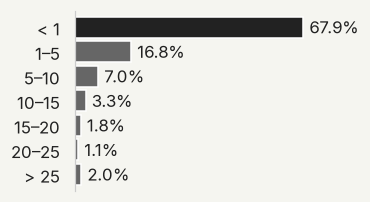

In [71]:
rain_counts_plot = RAIN_COUNTS.iloc[::-1]
fig, ax = plt.subplots(figsize=(3.5, 2), facecolor=FIG_BG)
rain_counts_plot.plot(
    kind="barh", width=0.85,
    color=["#666666"] * (len(rain_counts_plot) - 1) + ["#222222"], ax=ax,
)
ax.bar_label(
    ax.containers[0],
    labels=[f"{value:.1%}" for value in rain_counts_plot],
    padding=4, fontsize=11,
)
ax.set_ylabel("")
ax.set_xticks([])
ax.grid(False, axis="both")
ax.spines[["top", "right", "bottom"]].set_visible(False)
fig.tight_layout()
style_current_figure()
fig.savefig(FINAL_FIGURE_DIR / "rain proportion.png", dpi=600, bbox_inches="tight")
plt.show()
del rain_counts_plot

## PM2.5 response to rainfall amount

Each line shows the median daily PM2.5/pollutant concentration divided by that station's median for the same calendar month, grouped by same-day rainfall amount. The dashed reference is 1, the station-month median level.

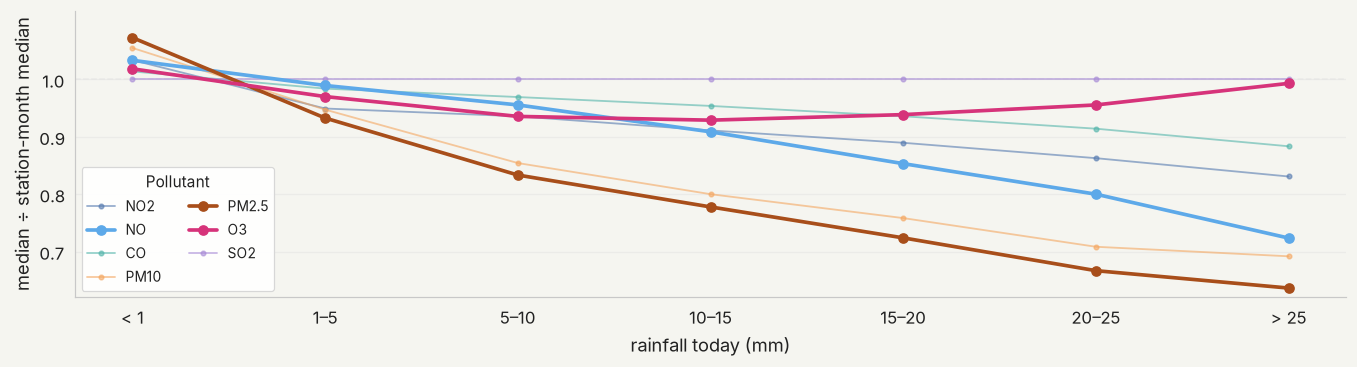

In [72]:
dose_plot = DOSE.reindex(index=RAIN_BIN_LABELS).reindex(
    columns=[p for p in POLLUTANT_ORDER if p in DOSE.columns]
)
fig, ax = plt.subplots(figsize=RAIN_DOSE_FIGSIZE, facecolor=FIG_BG)
x_positions = np.arange(len(RAIN_BIN_LABELS))
for pollutant in POLLUTANT_ORDER:
    if pollutant not in dose_plot.columns:
        continue
    key = pollutant_key(pollutant)
    emphasized = key in BOLD_POLLUTANTS
    ax.plot(
        x_positions, dose_plot[pollutant].to_numpy(dtype=float),
        color=PRIMARY_COLORS[key] if emphasized else SECONDARY_COLORS[key],
        linewidth=LINEWIDTH_PRIMARY if emphasized else LINEWIDTH_SECONDARY,
        alpha=LINE_ALPHA_PRIMARY if emphasized else LINE_ALPHA_SECONDARY,
        marker=RAIN_DOSE_MARKER,
        markersize=MARKERSIZE_PRIMARY if emphasized else MARKERSIZE_SECONDARY,
        label=POLLUTANT_LABELS[key], solid_capstyle="round",
        zorder=3 if emphasized else 2,
    )
ax.axhline(1.0, color=GRID_COLOR, alpha=GRID_ALPHA, linestyle="--", linewidth=1.0, zorder=1)
ax.set_xticks(x_positions, labels=RAIN_BIN_LABELS)
ax.set_xlabel("rainfall today (mm)")
ax.set_ylabel("median ÷ station-month median")
ax.set_ylim(*RAIN_DOSE_YLIM)
ax.set_yticks(RAIN_DOSE_YTICKS)
ax.grid(axis="y", color=GRID_COLOR, alpha=GRID_ALPHA, linewidth=0.8)
ax.grid(axis="x", visible=False)
ax.spines[["top", "right"]].set_visible(False)
ax.spines["left"].set_color("#c8c8c8")
ax.spines["bottom"].set_color("#c8c8c8")
ax.tick_params(axis="both", length=3)
legend = ax.legend(
    title="Pollutant", loc="lower left", ncol=2, frameon=True,
    framealpha=0.92, facecolor="white", edgecolor="#d5d5d5",
    fontsize=9, title_fontsize=10,
)
legend.get_frame().set_linewidth(0.8)
fig.tight_layout()
style_current_figure()
plt.show()
fig.savefig(FINAL_FIGURE_DIR / "rain by amount.png", dpi=600, bbox_inches="tight")
del dose_plot, x_positions

In [73]:
# Fisher–Freeman–Halton test (RxC extension of Fisher's exact test),
# The conditional Monte Carlo approximation fixes the observed row and column margins.
def fisher_freeman_halton_mc(table, n_resamples=FISHER_RESAMPLES, seed=FISHER_RANDOM_SEED):
    table = np.asarray(table, dtype=np.int64)
    if table.ndim != 2 or table.size == 0:
        return np.nan, 0
    table = table[table.sum(axis=1) > 0]
    table = table[:, table.sum(axis=0) > 0]
    if min(table.shape) < 2:
        return np.nan, int(table.sum())

    row_sums = table.sum(axis=1)
    col_sums = table.sum(axis=0)
    n_total = int(table.sum())
    constant = (
        gammaln(row_sums + 1).sum()
        + gammaln(col_sums + 1).sum()
        - gammaln(n_total + 1)
    )
    observed_log_probability = constant - gammaln(table + 1).sum()
    simulated = stats.random_table.rvs(
        row_sums, col_sums, size=n_resamples,
        random_state=np.random.default_rng(seed),
    )
    simulated_log_probability = constant - gammaln(simulated + 1).sum(axis=(1, 2))
    # Probability-ordering two-sided Fisher–Freeman–Halton p-value.
    extreme = np.count_nonzero(simulated_log_probability <= observed_log_probability + 1e-12)
    p_value = (extreme + 1) / (n_resamples + 1)
    return float(p_value), n_total

if "PM25" not in df.columns or df["PM25"].notna().sum() == 0:
    print("Fisher test skipped: PM2.5 daily means are unavailable.")
else:
    # Concentration classes use the same PM2.5 upper bounds as the project's AQI proxy.
    PM25_CLASSES = ["≤ 5", "5–15", "15–50", "50–90", "90–140", "> 140"]
    pm25_class = pd.cut(
        df["PM25"],
        bins=[-np.inf, 5, 15, 50, 90, 140, np.inf],
        labels=PM25_CLASSES, right=True, ordered=True,
    )
    rainy_test = pd.DataFrame({"rain_bin": RAIN_BINS, "PM25_class": pm25_class}).dropna()
    rainy_test = rainy_test[rainy_test["rain_bin"] != RAIN_BIN_LABELS[0]]
    rainy_order = RAIN_BIN_LABELS[1:]
    omnibus_table = pd.crosstab(rainy_test["rain_bin"], rainy_test["PM25_class"]).reindex(
        index=rainy_order, columns=PM25_CLASSES, fill_value=0,
    )
    omnibus_p, omnibus_n = fisher_freeman_halton_mc(omnibus_table.to_numpy())
    print(f"Omnibus rainy-day distribution test: n={omnibus_n:,}, p≈{omnibus_p:.5g}")
    display(omnibus_table)

    pairwise_rows = []
    for i, rain_bin in enumerate(rainy_order):
        selected = rainy_test["rain_bin"].eq(rain_bin)
        comparison_group = pd.Series(
            np.where(selected, rain_bin, "Other rainy bins"), index=rainy_test.index,
        )
        pair_table = pd.crosstab(comparison_group, rainy_test["PM25_class"]).reindex(
            index=[rain_bin, "Other rainy bins"], columns=PM25_CLASSES, fill_value=0,
        )
        p_raw, n_pair = fisher_freeman_halton_mc(
            pair_table.to_numpy(), seed=FISHER_RANDOM_SEED + i + 1,
        )
        pairwise_rows.append({
            "rainfall bin": rain_bin,
            "n in bin": int(pair_table.loc[rain_bin].sum()),
            "n other rainy days": int(pair_table.loc["Other rainy bins"].sum()),
            "p (raw)": p_raw,
        })

    FISHER_RESULTS = pd.DataFrame(pairwise_rows)
    n_tests = FISHER_RESULTS["p (raw)"].notna().sum()
    FISHER_RESULTS["p (Bonferroni)"] = (FISHER_RESULTS["p (raw)"] * max(n_tests, 1)).clip(upper=1)
    FISHER_RESULTS["significant (0.05)"] = FISHER_RESULTS["p (Bonferroni)"] < 0.05
    print(f"Pairwise tests: each rainfall bin vs all remaining rainy days; Bonferroni m={n_tests}.")
    display(FISHER_RESULTS.round({"p (raw)": 5, "p (Bonferroni)": 5}))

    print(
        "Interpretation note: the test compares categorical daily PM2.5 concentrations "
        "across rainfall-intensity groups. The station-day records are repeated within "
        "monitoring stations and over time, so independence is not guaranteed; treat "
        "these p-values as exploratory, not cluster-adjusted inference."
    )
    del rainy_test, pm25_class, comparison_group, pair_table

Omnibus rainy-day distribution test: n=297,110, p≈4.9998e-05


PM25_class,≤ 5,5–15,15–50,50–90,90–140,> 140
rain_bin,,,,,,
1–5,19378,89562,44249,2759,163,40
5–10,10938,38686,15138,730,38,7
10–15,5851,18176,6387,201,11,2
15–20,3412,10316,3417,86,1,0
20–25,2132,5811,1812,35,2,1
> 25,4372,10635,2727,33,2,0


Pairwise tests: each rainfall bin vs all remaining rainy days; Bonferroni m=6.


,rainfall bin,n in bin,n other rainy days,p (raw),p (Bonferroni),significant (0.05)
0,1–5,156151,140959,0.00005,0.0003,True
1,5–10,65537,231573,0.00005,0.0003,True
2,10–15,30628,266482,0.00005,0.0003,True
3,15–20,17232,279878,0.00005,0.0003,True
4,20–25,9793,287317,0.00005,0.0003,True
5,> 25,17769,279341,0.00005,0.0003,True


Interpretation note: the test compares categorical daily PM2.5 concentrations across rainfall-intensity groups. The station-day records are repeated within monitoring stations and over time, so independence is not guaranteed; treat these p-values as exploratory, not cluster-adjusted inference.


## Consecutive days without rain

The plotted value is the median pollutant concentration relative to its station-month median at each exact day-position since the last rainy day. Position 0 is a rainy day; position 1 is the first day after it.

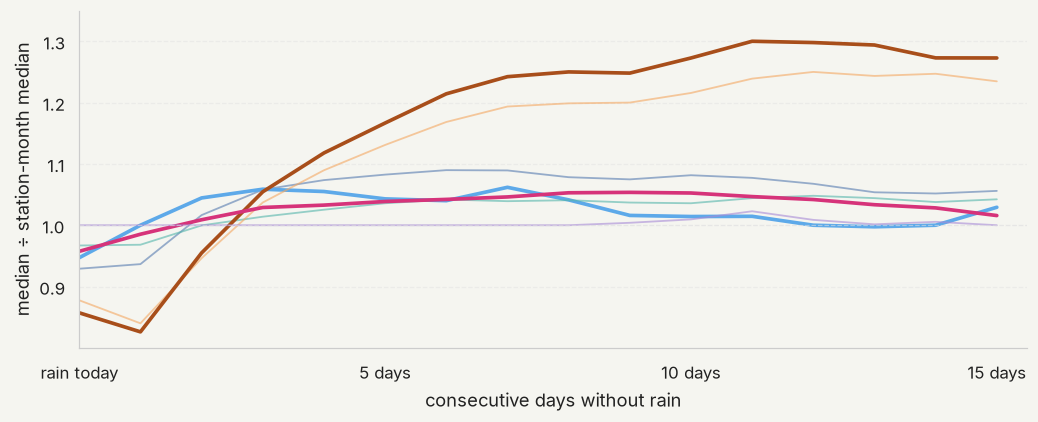

In [74]:
dry_x = np.arange(DRY_STREAK_MAX + 1)
fig, ax = plt.subplots(figsize=(12, 4), facecolor=FIG_BG)
for pollutant in POLLUTANT_ORDER:
    if pollutant not in DRY_STREAK_MEDIANS.columns:
        continue
    key = pollutant_key(pollutant)
    emphasized = key in BOLD_POLLUTANTS
    ax.plot(
        dry_x, DRY_STREAK_MEDIANS[pollutant].to_numpy(dtype=float),
        linewidth=LINEWIDTH_PRIMARY if emphasized else LINEWIDTH_SECONDARY,
        alpha=LINE_ALPHA_PRIMARY if emphasized else LINE_ALPHA_SECONDARY,
        label=POLLUTANT_LABELS[key],
        color=PRIMARY_COLORS[key] if emphasized else SECONDARY_COLORS[key],
    )
ax.set_xticks([0, 5, 10, 15], labels=["rain today", "5 days", "10 days", "15 days"])
ax.set_xlim(0, DRY_STREAK_MAX + 0.5)
ax.set_ylim(0.8, 1.35)
ax.set_yticks([0.9, 1.0, 1.1, 1.2, 1.3])
ax.axhline(1, color=GRID_COLOR, alpha=GRID_ALPHA, lw=0.8, ls="--")
ax.grid(axis="y", color=GRID_COLOR, alpha=GRID_ALPHA, lw=0.8, ls="--", zorder=0)
ax.grid(axis="x", visible=False)
ax.set_ylabel("median ÷ station-month median")
ax.set_xlabel("consecutive days without rain")
ax.spines[["top", "right"]].set_visible(False)
handles, labels = ax.get_legend_handles_labels()
handles_by_label = dict(zip(labels, handles))
ordered_labels = [POLLUTANT_LABELS[p] for p in POLLUTANT_ORDER if p in DRY_STREAK_MEDIANS.columns]
# fig.legend(
#     [handles_by_label[label] for label in ordered_labels], ordered_labels,
#     title="Pollutant", loc="upper right", fontsize=12, title_fontsize=14, ncol=2,
# )
fig.tight_layout(rect=[0, 0, 0.8, 1])
style_current_figure()
fig.savefig(FINAL_FIGURE_DIR / "no rain.png", dpi=600, bbox_inches="tight")
plt.show()
del dry_x, handles, labels, handles_by_label, ordered_labels

**Sample sizes behind the dry-spell curves**

Each cell counts valid station-day pollutant values contributing to the median in that exact streak-position bin. Values beyond day 15 are not included in the table or the plotted range.

In [75]:
DRY_STREAK_SAMPLE_TABLE = DRY_STREAK_COUNTS.T.reindex(
    index=[p for p in POLLUTANT_ORDER if p in DRY_STREAK_COUNTS.columns],
    columns=range(DRY_STREAK_MAX + 1),
)
DRY_STREAK_SAMPLE_TABLE.index = [POLLUTANT_LABELS[p] for p in DRY_STREAK_SAMPLE_TABLE.index]
DRY_STREAK_SAMPLE_TABLE.columns = [f"day {day}" for day in DRY_STREAK_SAMPLE_TABLE.columns]
display(DRY_STREAK_SAMPLE_TABLE)
print("Counts are station-day observations with a finite pollutant/month-median ratio, not unique stations or hourly records.")

,day 0,day 1,day 2,day 3,day 4,day 5,day 6,day 7,day 8,day 9,day 10,day 11,day 12,day 13,day 14,day 15
NO2,671191,282127,205874,157936,122053,96746,79306,65117,53822,45186,38125,32689,27788,23918,20985,18374
NO,161215,65502,46731,35293,26713,20651,16734,13623,11146,9477,8079,6748,5781,4993,4314,3834
CO,222756,95258,69983,53996,42076,33576,27462,22580,18665,15596,13126,11273,9511,8210,7196,6299
PM10,588297,246447,179555,137608,106450,84409,69266,56927,47004,39364,33161,28416,24194,20816,18145,15961
PM2.5,297110,123387,89955,68838,53380,42390,34698,28456,23366,19499,16404,14051,11888,10219,8866,7774
O3,381552,156397,112877,85683,65546,51759,42153,34506,28360,23692,19930,17053,14446,12501,11006,9646
SO2,213246,91326,67368,52206,41011,32858,27032,22413,18655,15796,13387,11603,9900,8508,7499,6601


Counts are station-day observations with a finite pollutant/month-median ratio, not unique stations or hourly records.


## Lagged rainfall correlation

A positive lag means rainfall occurred before the pollutant observation. The same precomputed 31-day anomalies are reused; only the rainfall lag series is shifted.

In [76]:
LAGS = range(-1, 5)
ns = df[STATION_COL].nunique()
nd = df[TIME_COL].nunique()

def shift_station_days(values, lag):
    matrix = np.asarray(values, dtype="float32").reshape(ns, nd)
    shifted = np.full_like(matrix, np.nan)
    if lag > 0:
        shifted[:, lag:] = matrix[:, :-lag]
    elif lag < 0:
        shifted[:, :lag] = matrix[:, -lag:]
    else:
        shifted[:] = matrix
    return shifted.reshape(-1)

rain_anomaly = df["an_rain"].to_numpy(dtype="float32")
lag_rows = []
for pollutant in POLL:
    y = df[f"an_{pollutant}"].to_numpy(dtype="float32")
    for lag_value in LAGS:
        rho, n_pairs = spearman(y, shift_station_days(rain_anomaly, lag_value))
        lag_rows.append((pollutant, "rain", lag_value, rho, n_pairs))
lag = pd.DataFrame(lag_rows, columns=["pollutant", "climate", "lag", "r", "n"])
del rain_anomaly, y, shift_station_days, ns, nd
gc.collect()

10148

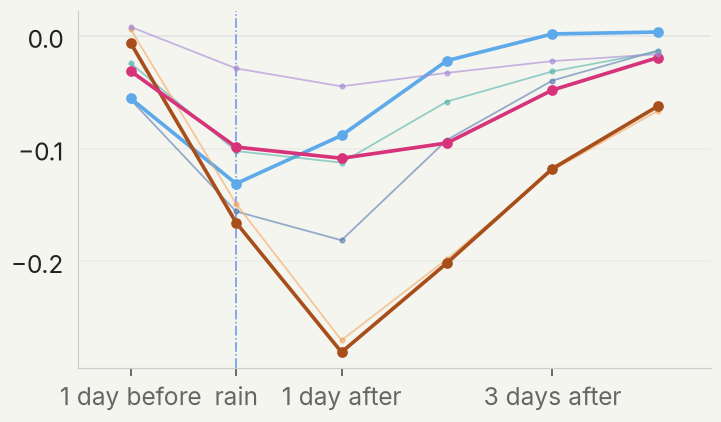

In [77]:
rain_lag = lag
fig, ax = plt.subplots(figsize=(8, 4), facecolor=FIG_BG)
ax.axhline(0, lw=1.3, color=GRID_COLOR, alpha=GRID_ALPHA, linestyle="-")
ax.axvline(0, lw=1, color="cornflowerblue", linestyle="-.")
for pollutant in POLL:
    d = rain_lag[rain_lag["pollutant"] == pollutant].sort_values("lag")
    key = pollutant_key(pollutant)
    emphasized = key in BOLD_POLLUTANTS
    ax.plot(
        d["lag"], d["r"], marker="o",
        linewidth=LINEWIDTH_PRIMARY if emphasized else LINEWIDTH_SECONDARY,
        alpha=LINE_ALPHA_PRIMARY if emphasized else LINE_ALPHA_SECONDARY,
        markersize=MARKERSIZE_PRIMARY if emphasized else MARKERSIZE_SECONDARY,
        label=POLLUTANT_LABELS[key],
        color=PRIMARY_COLORS[key] if emphasized else SECONDARY_COLORS[key],
    )
ax.set_xticks([-1, 0, 1, 3], labels=["1 day before", "rain", "1 day after", "3 days after"], fontsize=8)
ax.set_yticks([-0.2, -0.1, 0])
ax.tick_params(axis="both", labelsize=16)
ax.set_xlim(-1.5, 4.5)
ax.grid(False, axis="x")
ax.grid(axis="y", color=GRID_COLOR, alpha=GRID_ALPHA)
ax.tick_params(axis="x", bottom=True, labelbottom=True, colors="#666666", length=5)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(rect=(0, 0, 0.84, 1))
style_current_figure()
fig.savefig(FINAL_FIGURE_DIR / "spearman_rain.png", dpi=600, bbox_inches="tight")
plt.show()
del rain_lag, d

## Ventilation factors

The three panels reuse the same station-month-normalized pollutant series and compare wind speed, boundary-layer height and their product (ventilation coefficient).

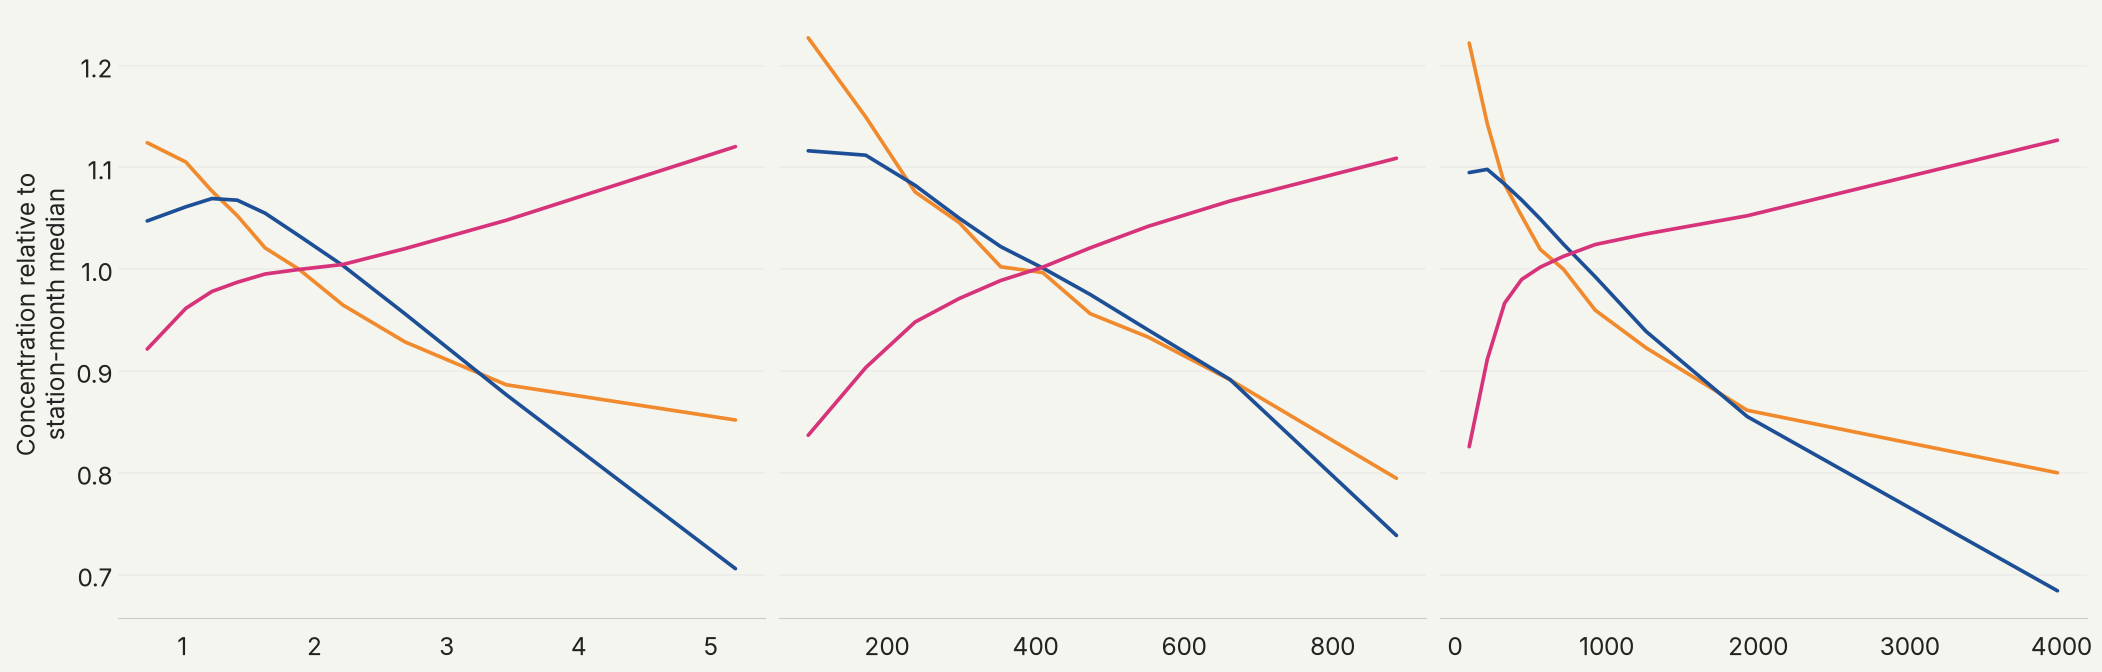

In [78]:
WIND_FIGSIZE = (19, 6)
WIND_TICK_LABEL_SIZE = 16
WIND_MAX_TICKS = 5
fig, axes = plt.subplots(1, 3, figsize=WIND_FIGSIZE, sharey=True, facecolor=FIG_BG, constrained_layout=True)
for i, (ax, (variable, (x_values, y_values))) in enumerate(zip(axes, WIND_EFFECT_DATA.items())):
    for pollutant in WIND_EFFECT_POLLUTANTS:
        key = pollutant_key(pollutant)
        emphasized = True # key in BOLD_POLLUTANTS
        ax.plot(
            x_values, y_values[pollutant],
            linewidth=LINEWIDTH_PRIMARY if emphasized else LINEWIDTH_SECONDARY,
            color=PRIMARY_COLORS[key] if emphasized else SECONDARY_COLORS[key],
            alpha=LINE_ALPHA_PRIMARY if emphasized else LINE_ALPHA_SECONDARY,
            label=POLLUTANT_LABELS[key] if i == 0 else None,
            solid_capstyle="round",
        )
    ax.xaxis.set_major_locator(mticker.MaxNLocator(nbins=WIND_MAX_TICKS, prune=None))
    ax.tick_params(axis="x", labelsize=WIND_TICK_LABEL_SIZE, length=5, width=1.2)
    ax.tick_params(axis="y", labelsize=WIND_TICK_LABEL_SIZE, length=0)
    ax.yaxis.set_major_locator(mticker.MultipleLocator(0.1))
    ax.grid(axis="y", color=GRID_COLOR, alpha=GRID_ALPHA, linewidth=1)
    ax.grid(False, axis="x")
    ax.spines["left"].set_visible(False)
axes[0].set_ylabel("Concentration relative to\nstation-month median", fontsize=WIND_TICK_LABEL_SIZE)
style_current_figure()
fig.savefig(FINAL_FIGURE_DIR / "Wind_effect2.png", dpi=600, bbox_inches="tight", facecolor=FIG_BG)
plt.show()
del axes

## Humidity, ventilation and weather regimes

Station metadata, humidity classes and the six mutually exclusive weather regimes are derived from the same shared station-day table. The original complete daily grid already contains the rainfall-history and rolling-humidity fields, so no second station-by-station reindexing pass is needed.

In [79]:
# Calendar labels used by the seasonal composition and stagnation summaries.
df["year"] = df[TIME_COL].dt.year.astype("int16")
df["season"] = df["month"].map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn",
})


In [80]:
def local_month_quantile(frame, value_col, q, min_n=MIN_LOCAL_DAYS):
    def qfun(s):
        s = s.dropna()
        return s.quantile(q) if len(s) >= min_n else np.nan
    return frame.groupby([STATION_COL, "month"], sort=False)[value_col].transform(qfun)

df["RH_Q25"] = local_month_quantile(df, "RH_3d_mean", LOCAL_Q_LOW)
df["RH_Q75"] = local_month_quantile(df, "RH_3d_mean", LOCAL_Q_HIGH)
df["RH_class"] = np.select(
    [df["RH_3d_mean"] < df["RH_Q25"], df["RH_3d_mean"] > df["RH_Q75"]],
    ["Low RH", "High RH"], default="Intermediate RH"
)
df.loc[df[["RH_3d_mean", "RH_Q25", "RH_Q75"]].isna().any(axis=1), "RH_class"] = np.nan

df["VENT_Q25"] = local_month_quantile(df, "vent", LOCAL_Q_LOW)
df["VENT_Q75"] = local_month_quantile(df, "vent", LOCAL_Q_HIGH)
df["VENT_class"] = np.select(
    [df["vent"] < df["VENT_Q25"], df["vent"] > df["VENT_Q75"]],
    ["Low ventilation", "High ventilation"], default="Intermediate ventilation"
)
df.loc[df[["vent", "VENT_Q25", "VENT_Q75"]].isna().any(axis=1), "VENT_class"] = np.nan

df["dry_spell_valid"] = df["dry_spell"] & df["rain_free_today"]
df["stagnant_dry"] = df["dry_spell_valid"] & df["VENT_class"].eq("Low ventilation")
df["ventilated_dry"] = df["dry_spell_valid"] & df["VENT_class"].eq("High ventilation")

print("Humidity classes:")
display(df["RH_class"].value_counts(dropna=False).to_frame("station_days"))
print("Ventilation classes:")
display(df["VENT_class"].value_counts(dropna=False).to_frame("station_days"))


Humidity classes:


,station_days
RH_class,
Intermediate RH,1492465
Low RH,747720
High RH,747719
NaN,744


Ventilation classes:


,station_days
VENT_class,
Intermediate ventilation,1493208
High ventilation,747720
Low ventilation,747720


In [81]:
# Six mutually exclusive categories, in the user's requested order.
REGIME_ORDER = [
    "Rainy",
    "Short rain-free interval",
    "Dry spell + low RH",
    "Dry spell + intermediate RH",
    "Dry spell + high RH",
    "Other",
]

# Assign the simple precipitation-persistence classes first.
df["weather_regime"] = "Other"
df.loc[df["rainy_today"], "weather_regime"] = "Rainy"
df.loc[
    df["rain_free_today"] & df["dry_run"].between(1, DRY_SPELL_DAYS - 1),
    "weather_regime"
] = "Short rain-free interval"

# For established dry spells, classify only by RH; ventilation remains a separate
# dimension used by the stagnation-uplift comparison and the RH × ventilation heatmap.
rh_regime_map = {
    "Low RH": "Dry spell + low RH",
    "Intermediate RH": "Dry spell + intermediate RH",
    "High RH": "Dry spell + high RH",
}
for rh_class, regime in rh_regime_map.items():
    mask = df["dry_spell_valid"] & df["RH_class"].eq(rh_class)
    df.loc[mask, "weather_regime"] = regime

# Any missing rainfall history or missing RH on a dry-spell day remains 'Other'.
# This preserves the six requested categories without treating missing data as dry.
df.loc[~df["rain_known"], "weather_regime"] = "Other"
df.loc[df["dry_spell_valid"] & df["RH_class"].isna(), "weather_regime"] = "Other"
df["weather_regime"] = pd.Categorical(
    df["weather_regime"], categories=REGIME_ORDER, ordered=True
)

print("Weather regime composition (% station-days):")
display(
    (df["weather_regime"].value_counts(normalize=True)
     .reindex(REGIME_ORDER).fillna(0).mul(100))
    .round(1).to_frame("percent")
)
season_mix = (
    pd.crosstab(df["season"], df["weather_regime"], normalize="index")
    .reindex(columns=REGIME_ORDER) * 100
)
display(season_mix.round(1))


Weather regime composition (% station-days):


,percent
weather_regime,
Rainy,32.1
Short rain-free interval,23.2
Dry spell + low RH,16.9
Dry spell + intermediate RH,22.2
Dry spell + high RH,5.6
Other,0.1


weather_regime,Rainy,Short rain-free interval,Dry spell + low RH,Dry spell + intermediate RH,Dry spell + high RH,Other
season,,,,,,
Autumn,34.5,24.4,16.0,20.4,4.8,0.0
Spring,35.5,24.8,16.8,19.3,3.7,0.0
Summer,27.0,21.0,18.8,26.9,6.4,0.0
Winter,31.3,22.7,16.1,22.2,7.5,0.3


## Humidity × ventilation

The panel is restricted to rain-free days at least three days after the previous rain. PM2.5 is expressed relative to the station-month median; each cell summarizes station-level medians.

In [82]:
dry = df[df["dry_spell_valid"]].copy()
dry = dry.dropna(subset=["PM25", "RH_3d_mean", "vent"])
dry["RH_fixed_bin"] = pd.cut(
    dry["RH_3d_mean"], bins=[-np.inf, 50, 70, 85, np.inf],
    labels=["<50%", "50–70%", "70–85%", "≥85%"], right=False,
)
dry["VENT_Q5"] = df.loc[dry.index, "vent"].groupby(
    [df.loc[dry.index, STATION_COL], df.loc[dry.index, "month"]], sort=False,
).rank(method="first", pct=True).mul(5).apply(np.ceil).clip(1, 5)
dry["PM25_anomaly_pct"] = 100 * (PM25_NORM.loc[dry.index].to_numpy(dtype="float32") - 1)
dry.loc[~np.isfinite(dry["PM25_anomaly_pct"]), "PM25_anomaly_pct"] = np.nan

cell_station = (
    dry.dropna(subset=["VENT_Q5", "RH_fixed_bin", "PM25_anomaly_pct"])
    .groupby([STATION_COL, "VENT_Q5", "RH_fixed_bin"], observed=True)
    .agg(station_cell_anomaly=("PM25_anomaly_pct", "median"))
    .reset_index()
)
heat = cell_station.groupby(["VENT_Q5", "RH_fixed_bin"], observed=True).agg(
    anomaly_pct=("station_cell_anomaly", "median"),
    n_stations=(STATION_COL, "nunique"),
).reset_index()
heat_matrix = heat.pivot(index="VENT_Q5", columns="RH_fixed_bin", values="anomaly_pct").reindex(
    index=[1, 2, 3, 4, 5], columns=["<50%", "50–70%", "70–85%", "≥85%"],
)
n_matrix = heat.pivot(index="VENT_Q5", columns="RH_fixed_bin", values="n_stations").reindex_like(heat_matrix)

In [83]:
# fig, ax = plt.subplots(figsize=(8.4, 5.0), facecolor=FIG_BG)
# annot = np.empty(heat_matrix.shape, dtype=object)
# for i in range(heat_matrix.shape[0]):
#     for j in range(heat_matrix.shape[1]):
#         value, n_st = heat_matrix.iloc[i, j], n_matrix.iloc[i, j]
#         annot[i, j] = "" if pd.isna(value) else f"{value:+.0f}%\n(n={int(n_st) if pd.notna(n_st) else 0})"
# sns.heatmap(
#     heat_matrix, annot=annot, fmt="", cmap="RdYlBu_r", center=0,
#     cbar_kws={"label": "PM₂.₅ anomaly vs station-month median (%)"},
#     linewidths=0.5, linecolor="white", ax=ax, mask=heat_matrix.isna(),
# )
# ax.set_yticklabels(["Q1 · most stagnant", "Q2", "Q3", "Q4", "Q5 · most ventilated"], rotation=0)
# ax.set_xlabel("3-day mean relative humidity")
# ax.set_ylabel("Ventilation quintile (station-month specific)")
# plt.tight_layout()
# style_current_figure()
# plt.show()
# display(heat_matrix.round(1))
# del dry, cell_station, heat, heat_matrix, n_matrix, annot
# # Release the one retained full-length normalized series after its last use.
# del PM25_NORM
# gc.collect()

## Stagnation uplift by pollutant

A dry day is stagnant when its ventilation falls in the lower station-month quartile; the comparison group is other non-rainy days. Uplift is computed within station-months and then summarized at station level.

In [84]:
# Use the canonical pollutant order and labels defined in the shared configuration.
POLLUTANTS = [p for p in POLL if p in df.columns and df[p].notna().any()]

if not POLLUTANTS:
    raise ValueError("No df-mean pollutant columns were found for the uplift box plot.")

uplift_rows = []

for pollutant in POLLUTANTS:
    q = df.dropna(subset=[pollutant]).copy()
    q["is_stagnant"] = q["stagnant_dry"].fillna(False)
    q["to_compare"] = (~ q["stagnant_dry"] & (q["weather_regime"] != "Rainy")).fillna(False)
    for (station, month, year), g in q.groupby([STATION_COL, "month", "year"], observed=True, sort=False):
        stagnant_values = g.loc[g["is_stagnant"], pollutant].dropna()
        other_values = g.loc[g["to_compare"], pollutant].dropna()
        if len(stagnant_values) >= MIN_COMPARE_N and len(other_values) >= MIN_COMPARE_N:
            stagnant_median = float(stagnant_values.median())
            other_median = float(other_values.median())
            if np.isfinite(other_median) and other_median > 0:
                uplift_rows.append({
                    STATION_COL: station,
                    "month": month,
                    "year": year,
                    "pollutant": pollutant,
                    "stagnant_n": len(stagnant_values),
                    "other_n": len(other_values),
                    "stagnant_median": stagnant_median,
                    "other_median": other_median,
                    "uplift_pct": 100 * (stagnant_median / other_median - 1),
                })

uplift_month = pd.DataFrame(uplift_rows)
if uplift_month.empty:
    raise ValueError(
        "No station-month groups meet the minimum sample requirement for stagnation uplift. "
        "Consider reducing MIN_COMPARE_N or checking stagnant_dry coverage."
    )

# One comparable value per station and pollutant: median across eligible months.
uplift_station = (
    uplift_month.groupby([STATION_COL, "pollutant"], observed=True)
    .agg(
        uplift_pct=("uplift_pct", "median"),
        n_station_months=("month", "nunique"),
        stagnant_days=("stagnant_n", "sum"),
        other_days=("other_n", "sum"),
    )
    .reset_index()
)


In [85]:
rng = np.random.default_rng(RANDOM_SEED)

def bootstrap_median_ci(values, reps=BOOTSTRAP_REPS, alpha=0.05):
    """Return the 95% interval for the resampled station-level median."""
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    if len(x) < 2:
        return (np.nan, np.nan)
    bag = max(2, int(np.round(len(x) * 0.8)))
    draws = np.median(rng.choice(x, size=(reps, bag), replace=True), axis=1)
    return tuple(np.quantile(draws, [alpha / 2, 1 - alpha / 2]))


In [86]:
summary = (
    uplift_station.groupby("pollutant", observed=True)["uplift_pct"]
    .agg(n_stations="count", mean="mean", median="median", sd="std")
    .reindex(POLLUTANTS)
)
display(summary.rename(index=POLLUTANT_LABELS).round(2))


,n_stations,mean,median,sd
pollutant,,,,
NO2,706,25.74,20.24,18.81
NO,331,43.55,34.89,42.80
CO,268,14.08,13.11,9.03
PM10,641,31.03,28.91,17.37
PM2.5,340,38.87,38.46,16.32
O3,401,-12.06,-11.33,10.28
SO2,272,8.51,4.07,17.56


In [87]:


box_stats, positions, kept_pollutants = [], [], []
for i, pollutant in enumerate(POLLUTANTS):
    x = uplift_station.loc[uplift_station["pollutant"] == pollutant, "uplift_pct"].dropna().to_numpy()
    if len(x) < MIN_STATIONS_FOR_BOX:
        continue
    q1, med, q3 = np.quantile(x, [0.25, 0.50, 0.75])
    iqr = q3 - q1
    lower = x[x >= q1 - 1.5 * iqr]
    upper = x[x <= q3 + 1.5 * iqr]
    ci_lo, ci_hi = bootstrap_median_ci(x, alpha = 0.05)
    box_stats.append({
        "label": POLLUTANT_LABELS[pollutant],
        "q1": q1,
        "med": med,
        "q3": q3,
        "whislo": float(lower.min()) if len(lower) else float(x.min()),
        "whishi": float(upper.max()) if len(upper) else float(x.max()),
        "mean": float(x.mean()),
        "cilo": ci_lo,
        "cihi": ci_hi,
        "fliers": np.concatenate((x[x >= q3 + 1.5 * iqr], x[x <= q1 - 1.5 * iqr])),
    })
    positions.append(i * BOX_SPACING)
    kept_pollutants.append(pollutant)


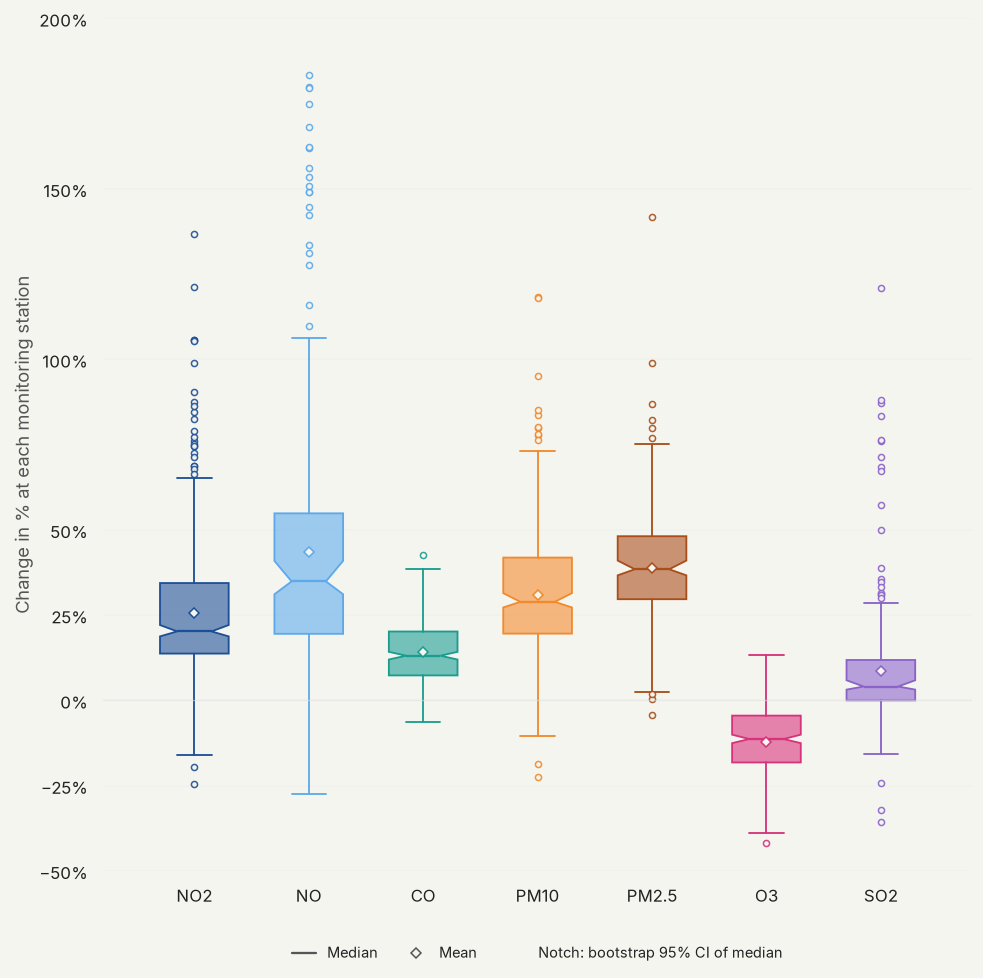

In [88]:

if box_stats:
    with plt.rc_context({"font.family": BOX_FONT}):
        fig, ax = plt.subplots(figsize=(max(7, BOX_FIG_WIDTH_PER_POLLUTANT * len(box_stats)), BOX_FIG_HEIGHT))
        fig.patch.set_facecolor(FIG_BG)
        ax.set_facecolor(FIG_BG)

        artists = ax.bxp(
            box_stats,
            positions=positions,
            widths=BOX_WIDTH,
            patch_artist=True,
            shownotches=True,
            showmeans=True,
            showfliers=True,
            meanprops={"marker": "D", "markersize": 5},
            medianprops={"linewidth": 1.5},
            whiskerprops={"linewidth": 1.2},
            capprops={"linewidth": 1.2},
            flierprops={"marker": "o", "markersize": 4},
        )

        for j, pollutant in enumerate(kept_pollutants):
            color_key = pollutant_key(POLLUTANT_LABELS[pollutant])
            edge = PRIMARY_COLORS[color_key]
            face = to_rgba(SECONDARY_COLORS[color_key], BOX_FACE_ALPHA)

            patch = artists["boxes"][j]
            patch.set_facecolor(face)
            patch.set_edgecolor(edge)
            patch.set_linewidth(1.2)

            artists["medians"][j].set_color(edge)
            artists["means"][j].set_markerfacecolor(FIG_BG)
            artists["means"][j].set_markeredgecolor(edge)

            for k in (2 * j, 2 * j + 1):
                artists["whiskers"][k].set_color(edge)
                artists["caps"][k].set_color(edge)

            artists["fliers"][j].set_markeredgecolor(edge)
            artists["fliers"][j].set_markerfacecolor(FIG_BG)
            artists["fliers"][j].set_alpha(0.9)

        ax.axhline(0, color=GRID_COLOR, alpha=GRID_ALPHA, lw=0.9)
        ax.set_xticks(positions, [d["label"] for d in box_stats])
        ax.set_yticks([-50, -25, 0, 25, 50, 100, 150, 200])
        ax.set_xlim(positions[0] - 0.6, positions[-1] + 0.6)
        ax.set_ylim(-50, 200)
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))  # 50 -> "50%"
        ax.grid(axis="y", alpha=0.25)
        ax.grid(axis="x", visible=False)
        for spine in ax.spines.values():
            spine.set_visible(False)

        ax.set_ylabel(BOX_YLABEL, color=BOX_NEUTRAL)

        handles = [
            Line2D([], [], color=BOX_NEUTRAL, lw=1.5, label="Median"),
            Line2D([], [], color=FIG_BG, marker="D", markersize=5, linestyle="none", label="Mean", markeredgecolor=BOX_NEUTRAL),
            Line2D([], [], color="none", label="Notch: bootstrap 95% CI of median"),
        ]
        ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.07),
                  ncol=3, frameon=False, fontsize=9.5, columnspacing=1.8, handlelength=1.6)

        plt.tight_layout()
        style_current_figure()
        plt.savefig(FINAL_FIGURE_DIR / "boxplot stagnation.png", dpi=600)
        plt.show()
else:
    print(f"No pollutant had at least {MIN_STATIONS_FOR_BOX} eligible stations for the box plot.")


## WHO threshold exceedances and AQI

Threshold exceedances are calculated from daily pollutant means (and the daily O₃ maximum where available), then averaged across stations within each weather regime. The four-column threshold matrix in the presentation uses the AQI class cutoff of 4, not the continuous AQHI index.

In [89]:
# # Derive a project-consistent AQI_hi proxy if no precomputed AQI_hi is in raw.csv.
# def class_from_upper_bounds(series, bounds):
#     values = pd.to_numeric(series, errors="coerce")
#     arr = np.searchsorted(np.asarray(bounds, dtype=float), values.to_numpy(dtype=float), side="left") + 1
#     return pd.Series(arr.astype(float), index=series.index).where(values.notna())

# if "AQI_hi" in df and df["AQI_hi"].notna().any():
#     df["AQI_hi_used"] = pd.to_numeric(df["AQI_hi"], errors="coerce")
#     aqi_source_note = "AQI_hi supplied in raw.csv"
# else:
#     aqi_parts = {}
#     if "PM25" in df: aqi_parts["PM25"] = class_from_upper_bounds(df["PM25"], [5, 15, 50, 90, 140])
#     if "PM10" in df: aqi_parts["PM10"] = class_from_upper_bounds(df["PM10"], [15, 45, 120, 195, 270])
#     no2_source = df["NO2_max"] if "NO2_max" in df and df["NO2_max"].notna().any() else df["NO2"]
#     if no2_source.notna().any(): aqi_parts["NO2"] = class_from_upper_bounds(no2_source, [10, 25, 60, 100, 150])
#     o3_source = df["O3_max"] if "O3_max" in df and df["O3_max"].notna().any() else df.get("O3", pd.Series(np.nan, index=df.index))
#     if o3_source.notna().any(): aqi_parts["O3"] = class_from_upper_bounds(o3_source, [60, 100, 120, 160, 180])
#     so2_source = df["SO2_max"] if "SO2_max" in df and df["SO2_max"].notna().any() else df.get("SO2", pd.Series(np.nan, index=df.index))
#     if so2_source.notna().any(): aqi_parts["SO2"] = class_from_upper_bounds(so2_source, [20, 40, 125, 190, 275])
#     aqi_df = pd.DataFrame(aqi_parts)
#     df["AQI_hi_used"] = aqi_df.max(axis=1, skipna=True).where(aqi_df.notna().sum(axis=1) >= 2) if not aqi_df.empty else np.nan
#     aqi_source_note = "AQI_hi proxy derived from df summaries; requires at least two pollutant classes"
# print("AQI indicator:", aqi_source_note)

# threshold_columns = {}
# for col, threshold, label in [
#     ("PM25", 15, "PM₂.₅ > 15 µg/m³"),
#     ("PM10", 45, "PM₁₀ > 45 µg/m³"),
#     ("NO2", 25, "NO₂ > 25 µg/m³"),
# ]:
#     if col in df and df[col].notna().any():
#         flag = "EX_" + col
#         df[flag] = (df[col] > threshold).astype(float).where(df[col].notna())
#         threshold_columns[label] = flag
# if "O3_max" in df and df["O3_max"].notna().any():
#     df["EX_O3_max_180"] = (df["O3_max"] > 180).astype(float).where(df["O3_max"].notna())
#     threshold_columns["O₃ df max > 180 µg/m³"] = "EX_O3_max_180"
# df["EX_AQI_hi_ge4"] = (df["AQI_hi_used"] >= AQI_CLASS_THRESHOLD).astype(float).where(df["AQI_hi_used"].notna())
# threshold_columns[f"AQI_hi ≥ {AQI_CLASS_THRESHOLD:g}"] = "EX_AQI_hi_ge4"

# # Use the six requested categories directly; do not cross them with ventilation classes.
# df["weather_regime_label"] = df["weather_regime"].astype("string")

# def station_balanced_exceedance(frame, months=None):
#     q = frame if months is None else frame[frame["month"].isin(months)]
#     rows = []
#     for label, flag_col in threshold_columns.items():
#         z = q.dropna(subset=[flag_col, "weather_regime_label"])
#         station_rates = (
#             z.groupby([STATION_COL, "weather_regime_label"], observed=True)
#              .agg(rate=(flag_col, "mean"), n_days=(flag_col, "size"))
#              .reset_index()
#         )
#         station_rates = station_rates[station_rates["n_days"] >= MIN_STATION_GROUP_DAYS]
#         if station_rates.empty:
#             continue
#         out = (
#             station_rates.groupby("weather_regime_label", observed=True)
#             .agg(
#                 exceedance_pct=("rate", lambda x: x.mean() * 100),
#                 n_stations=(STATION_COL, "nunique"),
#                 median_days_per_station=("n_days", "median"),
#             )
#             .reset_index()
#         )
#         out["threshold"] = label
#         rows.append(out)
#     return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

# all_year_rates = station_balanced_exceedance(df)
# winter_rates = station_balanced_exceedance(df, WINTER_MONTHS)


In [90]:
# fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharey=True)
# for ax, dat in [
#     (axes[0], all_year_rates),
#     (axes[1], winter_rates),
# ]:
#     if dat.empty:
#         ax.text(.5, .5, "No adequate data", ha="center", va="center", transform=ax.transAxes)
#         ax.set_axis_off()
#         continue
#     mat = dat.pivot(index="weather_regime_label", columns="threshold", values="exceedance_pct")
#     mat = mat.reindex(index=REGIME_ORDER, columns=list(threshold_columns.keys()))
#     sns.heatmap(
#         mat, annot=True, fmt=".0f", cmap="YlOrRd", vmin=0, vmax=100,
#         linewidths=.5, linecolor="white", cbar=(ax is axes[1]),
#         cbar_kws={"label": "% station-balanced days exceeding threshold"} if ax is axes[1] else None,
#         ax=ax, mask=mat.isna(),
#     )
#     ax.set_xlabel("Threshold")
#     ax.set_ylabel("Weather regime" if ax is axes[0] else "")
#     ax.tick_params(axis="x", rotation=35, labelsize=8)
#     ax.tick_params(axis="y", labelsize=9)
# plt.tight_layout()
# style_current_figure()
# plt.show()
# print("Threshold definitions:")
# display(pd.DataFrame({"threshold": list(threshold_columns.keys()), "column": list(threshold_columns.values())}))


## AQHI threshold and continuous level

This supplementary panel keeps the continuous `AQHI_hi` level separate from the threshold exceedance share. The cutoff is controlled by `AQHI_THRESHOLD` in the shared configuration cell; it is not hard-coded into a precomputed flag.

In [91]:
df.columns

Index(['AirQualityStation', 'time', 'NO2', 'NO', 'CO', 'PM10', 'PM25', 'O3', 'SO2', 'wind', 'blh', 'vent', 't2m', 'rh', 'ssr', 'tp', 'AQI_hi', 'AQHI_hi', 'EX_PM10_WHO45',
       'EX_PM25_WHO15', 'EX_NO2_WHO25', 'NO2_max', 'O3_max', 'SO2_max', 'an_NO2', 'an_NO', 'an_CO', 'an_PM10', 'an_PM25', 'an_O3', 'an_SO2', 'an_wind', 'an_blh', 'an_vent',
       'an_t2m', 'an_rh', 'an_ssr', 'an_rain', 'st', 'month', 'dow', 'sm', 'tp_mm', 'RF_0', 'RF_heavy0', 'dry_run', 'rain_known', 'rainy_today', 'rain_free_today', 'dry_spell',
       'RH_3d_mean', 'year', 'season', 'RH_Q25', 'RH_Q75', 'RH_class', 'VENT_Q25', 'VENT_Q75', 'VENT_class', 'dry_spell_valid', 'stagnant_dry', 'ventilated_dry',
       'weather_regime'],
      dtype='str')

In [92]:
AQHI_THRESHOLD = 7

AQHI_REGIME_NAMES = ["Rainy", "Stagnant dry", "Ventilated dry", "Other"]
vent_q25 = df.groupby("sm", sort=False)["vent"].transform("quantile", 0.25)
vent_q75 = df.groupby("sm", sort=False)["vent"].transform("quantile", 0.75)
rainy = df["RF_0"].eq(1).to_numpy()
dry3 = df["dry_run"].ge(DRY_SPELL_DAYS).to_numpy()
vent = df["vent"].to_numpy(dtype="float32")
regime = np.full(len(df), 3, dtype="int8")
regime[(vent > vent_q75.to_numpy()) & ~rainy] = 2
regime[(vent < vent_q25.to_numpy()) & dry3 & ~rainy] = 1
regime[rainy] = 0

base_flags = [
    ("EX_PM10_WHO45", "PM10\n(45 µg/m³)"),
    ("EX_PM25_WHO15", "PM2.5\n(15 µg/m³)"),
    ("EX_NO2_WHO25", "NO2\n(25 µg/m³)"),
]
exceedance = pd.DataFrame(index=AQHI_REGIME_NAMES)
for column, label in base_flags:
    if column in df.columns:
        values = pd.to_numeric(df[column], errors="coerce").to_numpy()
        exceedance[label] = [
            100 * np.nanmean(values[(regime == r) & np.isfinite(values)])
            if np.any((regime == r) & np.isfinite(values)) else np.nan
            for r in range(4)
        ]

if "AQHI_hi" not in df.columns or not df["AQHI_hi"].notna().any():
    raise ValueError("AQHI_hi is unavailable. Include it in daily_indices before running this panel.")
aqhi_values = pd.to_numeric(df["AQHI_hi"], errors="coerce").to_numpy(dtype="float32")
aqhi_flag = np.where(np.isfinite(aqhi_values), (aqhi_values >= AQHI_THRESHOLD).astype(float), np.nan)
exceedance[f"AQHI\n ≥ {AQHI_THRESHOLD:g}"] = [
    100 * np.nanmean(aqhi_flag[(regime == r) & np.isfinite(aqhi_flag)])
    if np.any((regime == r) & np.isfinite(aqhi_flag)) else np.nan
    for r in range(4)
]

valid_aqhi = np.isfinite(aqhi_values)
aqhi_level = pd.Series(
    [float(np.nanmedian(aqhi_values[(regime == r) & valid_aqhi]))
     if np.any((regime == r) & valid_aqhi) else np.nan for r in range(4)],
    index=AQHI_REGIME_NAMES, name="Median AQHI_hi",
)
print(f"AQHI threshold: {AQHI_THRESHOLD:g}; valid AQHI_hi station-days: {int(valid_aqhi.sum()):,}")

AQHI threshold: 7; valid AQHI_hi station-days: 499,644


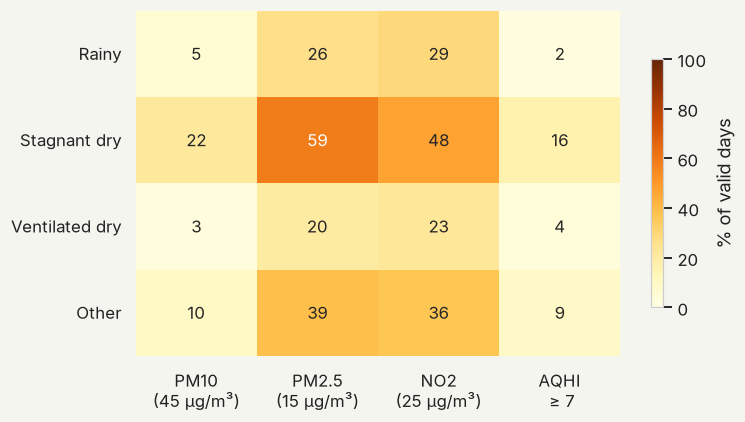

15766

In [93]:
# Visualization: separate scales for exceedance percentages and continuous AQHI level.

# This avoids mixing a percentage with the continuous AQHI formula proxy.
FIGSIZE = (7, 4)
CMAP_EXCEEDANCE = "YlOrBr"
CMAP_AQHI = "YlOrRd"
ANNOT_SIZE = 11
CBAR_SHRINK = 0.72

fig, ax = plt.subplots(
    1, 1, figsize=FIGSIZE, facecolor=FIG_BG,
    #gridspec_kw={"width_ratios": [1.5, 0.72]}
)
sns.heatmap(
    exceedance, annot=True, fmt=".0f", cmap=CMAP_EXCEEDANCE,
    vmin=0, vmax=100, ax=ax,
    annot_kws={"size": ANNOT_SIZE},
    cbar_kws={"shrink": CBAR_SHRINK, "label": "% of valid days"},
    # linewidth = .75
)
aqhi_frame = aqhi_level.to_frame()
# sns.heatmap(
#     aqhi_frame, annot=True, fmt=".2f", cmap=CMAP_AQHI,
#     vmin=0, vmax=max(10, float(np.nanmax(aqhi_level.to_numpy()))),
#     ax=axes[1], annot_kws={"size": ANNOT_SIZE},
#     cbar_kws={"shrink": CBAR_SHRINK, "label": "AQHI_hi"}
# )
# for ax in axes:
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
style_current_figure()
plt.savefig(FINAL_FIGURE_DIR / "exceedances.png")
plt.show()

del exceedance, aqhi_frame, aqhi_values, aqhi_level, aqhi_flag, valid_aqhi, regime, vent_q25, vent_q75, rainy, dry3, vent, base_flags
gc.collect()
